# 04 — Modelling (next-day AQI, 2023–2025 data)
**Input:** `data/Cleaned/aqi_2023_25_features.csv` (from notebook 03)

| Task | Target | Models | Metrics |
|---|---|---|---|
| A. Classification | tomorrow's `AQI_Bucket` | Logistic Regression, Random Forest, Hist Gradient Boosting | per-class precision/recall/F1, macro-F1, confusion matrix |
| B. Regression | tomorrow's `AQI` | Ridge, Random Forest, Hist Gradient Boosting | MAE, RMSE, R² |

## Four rules that make this valid
1. **Split by time, not randomly.** Train up to Oct 2024, test Nov 2024 – Apr 2025. The test period contains a full winter, the hardest and most important case. A random split would let neighbouring days leak between train and test.
2. **Baselines first.** "Tomorrow = today" (persistence) is strong. A model that does not beat it is not useful.
3. **Class imbalance:** use balanced class weights and judge by **macro-F1** (it treats rare classes like Severe equally). Accuracy alone would hide failure on rare classes.
4. **Tune with `TimeSeriesSplit`**, never shuffled folds, and make sure the rows are sorted by **date** first (shown below).

Runtime: on the full data (~240k rows) the Random Forests take a few minutes. Set `SAMPLE_FRAC` below 1 to try the notebook quickly.

In [1]:
import sys, os, time, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)

from src.aqi_common import CLASS_ORDER, TRAIN_END, TEST_START, ALL_FEATURES, build_preprocessor

sns.set_style("whitegrid")
FIG = "../reports/figures/2023_25"
for d in [FIG, "../models", "../reports"]:
    os.makedirs(d, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/2023_25_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

SAMPLE_FRAC = 1.0      # use e.g. 0.3 for a quick trial run
RUN_TUNING = True      # set False to skip the grid searches
MERGE_SEVERE = False   # True merges 'Very Poor' and 'Severe' (see the class balance below)
FEATURES = ALL_FEATURES

## Step 1 — Load and split by time
Training rows are those with `Date < 2024-10-31`; test rows have `Date >= 2024-11-01`. The days in between are left out on purpose: a row dated Oct 31 has its *label* (Nov 1) inside the test period, so keeping it would leak.

In [2]:
df = pd.read_csv("../data/Cleaned/aqi_2023_25_features.csv", parse_dates=['Date'])

def maybe_merge(s):
    return s.replace({'Very Poor': 'Very Poor/Severe', 'Severe': 'Very Poor/Severe'}) if MERGE_SEVERE else s

df['y_class'] = maybe_merge(df['target_bucket_next'])
df['today_class'] = maybe_merge(df['AQI_Bucket'])
base_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor/Severe'] if MERGE_SEVERE else CLASS_ORDER
labels = [c for c in base_order if c in set(df['y_class'])]

train = df[df['Date'] < TRAIN_END].copy()
test = df[df['Date'] >= TEST_START].copy()
if SAMPLE_FRAC < 1:
    train = train.sample(frac=SAMPLE_FRAC, random_state=0)

# sort by DATE (all cities together) - required for TimeSeriesSplit to cut along time
train = train.sort_values(['Date', 'City']).reset_index(drop=True)
test = test.sort_values(['Date', 'City']).reset_index(drop=True)

X_train, X_test = train[FEATURES], test[FEATURES]
print("Train:", len(train), train['Date'].min().date(), "->", train['Date'].max().date())
print("Test :", len(test), test['Date'].min().date(), "->", test['Date'].max().date())

dist = pd.concat([train['y_class'].value_counts(normalize=True).mul(100).round(1).rename('train %'),
                  test['y_class'].value_counts(normalize=True).mul(100).round(1).rename('test %')], axis=1)
dist.reindex(labels)

Train: 141433 2022-04-10 -> 2024-10-30
Test : 31826 2024-11-01 -> 2025-04-29


,train %,test %
y_class,,
Good,18.7,7.9
Satisfactory,38.2,33.0
Moderate,31.3,45.9
Poor,8.9,11.4
Very Poor,2.7,1.7
Severe,0.2,0.1


**Check the class balance above.** If *Severe* is a tiny share, a model cannot learn it. In that case set `MERGE_SEVERE = True`, rerun from the top, and state the choice in your report. The test period (winter) will also have fewer *Good* days than training, so the test set is harder.

## Step 2 — Metric helpers

In [3]:
def clf_metrics(y_true, y_pred, name):
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, y_pred),
            'MacroF1': f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0),
            'MacroPrecision': precision_score(y_true, y_pred, labels=labels, average='macro', zero_division=0),
            'MacroRecall': recall_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)}

def reg_metrics(y_true, y_pred, name):
    return {'Model': name,
            'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
            'R2': r2_score(y_true, y_pred)}

---
# Part A — Classification: tomorrow's AQI category

## Step 3 — Baselines
- *Always the most common class* (a floor).
- *Persistence:* tomorrow's category = today's category.

In [4]:
majority = train['y_class'].mode()[0]
res_clf = [
    clf_metrics(test['y_class'], [majority] * len(test), f"Baseline: always '{majority}'"),
    clf_metrics(test['y_class'], test['today_class'], "Baseline: tomorrow = today"),
]
pred_clf = {"Baseline: tomorrow = today": test['today_class'].to_numpy()}
pd.DataFrame(res_clf).round(3)

,Model,Accuracy,MacroF1,MacroPrecision,MacroRecall
0,Baseline: always 'Satisfactory',0.330,0.083,0.055,0.167
1,Baseline: tomorrow = today,0.707,0.592,0.590,0.594


**Takeaway:** *(persistence accuracy is the number to beat; note its macro-F1 too.)*

## Step 4 — Train the three classifiers
Each model is a `Pipeline` (preprocessing + model), so the same transformations are applied to train and test, and the city statistics are learned from training rows only.

**Takeaway:** *(does any model beat persistence on macro-F1? On accuracy? They can disagree, which is why we report both.)*

In [5]:
clf_models = {
    'Logistic Regression': Pipeline([('pre', build_preprocessor(FEATURES, scale=True)),
                                     ('m', LogisticRegression(max_iter=2000, class_weight='balanced'))]),
    'Random Forest': Pipeline([('pre', build_preprocessor(FEATURES)),
                               ('m', RandomForestClassifier(n_estimators=200, min_samples_leaf=10,
                                                            class_weight='balanced_subsample',
                                                            n_jobs=-1, random_state=42))]),
    'Hist Gradient Boosting': Pipeline([('pre', build_preprocessor(FEATURES)),
                                        ('m', HistGradientBoostingClassifier(class_weight='balanced',
                                                                             random_state=42))]),
}

fitted_clf = {}
for name, model in clf_models.items():
    t0 = time.time()
    model.fit(X_train, train['y_class'])
    fitted_clf[name] = model
    pred_clf[name] = model.predict(X_test)
    res_clf.append(clf_metrics(test['y_class'], pred_clf[name], name))
    print(f"{name:25s} trained in {time.time() - t0:5.1f}s")

res_clf_df = pd.DataFrame(res_clf).sort_values('MacroF1', ascending=False).reset_index(drop=True)
res_clf_df.round(3)

Logistic Regression       trained in  42.1s
Random Forest             trained in  37.0s
Hist Gradient Boosting    trained in  27.4s


,Model,Accuracy,MacroF1,MacroPrecision,MacroRecall
0,Baseline: tomorrow = today,0.707,0.592,0.590,0.594
1,Random Forest,0.693,0.584,0.567,0.614
2,Hist Gradient Boosting,0.683,0.577,0.550,0.629
3,Logistic Regression,0.671,0.538,0.501,0.649
4,Baseline: always 'Satisfactory',0.330,0.083,0.055,0.167


## Step 5 — Tune the gradient boosting model (time-ordered CV)
`TimeSeriesSplit` trains on earlier dates and validates on later ones. This only works because `train` is sorted by date.

In [6]:
if RUN_TUNING:
    tscv = TimeSeriesSplit(n_splits=4)
    grid = {'m__learning_rate': [0.05, 0.1], 'm__max_leaf_nodes': [15, 31]}
    gs = GridSearchCV(clf_models['Hist Gradient Boosting'], grid, cv=tscv, scoring='f1_macro', n_jobs=1)
    gs.fit(X_train, train['y_class'])
    print("Best parameters:", gs.best_params_, "| CV macro-F1:", round(gs.best_score_, 3))

    name = 'Hist Gradient Boosting (tuned)'
    fitted_clf[name] = gs.best_estimator_
    pred_clf[name] = gs.best_estimator_.predict(X_test)
    res_clf.append(clf_metrics(test['y_class'], pred_clf[name], name))
    res_clf_df = pd.DataFrame(res_clf).sort_values('MacroF1', ascending=False).reset_index(drop=True)
res_clf_df.round(3)

Best parameters: {'m__learning_rate': 0.05, 'm__max_leaf_nodes': 31} | CV macro-F1: 0.582


,Model,Accuracy,MacroF1,MacroPrecision,MacroRecall
0,Baseline: tomorrow = today,0.707,0.592,0.590,0.594
1,Random Forest,0.693,0.584,0.567,0.614
2,Hist Gradient Boosting (tuned),0.683,0.584,0.556,0.636
3,Hist Gradient Boosting,0.683,0.577,0.550,0.629
4,Logistic Regression,0.671,0.538,0.501,0.649
5,Baseline: always 'Satisfactory',0.330,0.083,0.055,0.167


## Step 6 — Per-class evaluation of the best model
Precision = of the days we flagged as a class, how many really were. Recall = of the days that really were that class, how many we caught. For *Severe* and *Very Poor*, recall is the number that matters for public health.

*Caution: "best" is picked using the test period, which slightly flatters it. In the report, say so, or choose using the cross-validation scores from the tuning step.*

In [7]:
best_clf_name = max(fitted_clf, key=lambda n: f1_score(test['y_class'], pred_clf[n], labels=labels, average='macro', zero_division=0))
print("Best classifier (by macro-F1):", best_clf_name, "\n")
print(classification_report(test['y_class'], pred_clf[best_clf_name], labels=labels, digits=3, zero_division=0))

print("\nFor comparison - persistence:\n")
print(classification_report(test['y_class'], test['today_class'], labels=labels, digits=3, zero_division=0))

Best classifier (by macro-F1): Random Forest 

              precision    recall  f1-score   support

        Good      0.701     0.714     0.708      2506
Satisfactory      0.761     0.643     0.697     10493
    Moderate      0.746     0.734     0.740     14619
        Poor      0.475     0.684     0.561      3637
   Very Poor      0.371     0.508     0.429       531
      Severe      0.348     0.400     0.372        40

    accuracy                          0.693     31826
   macro avg      0.567     0.614     0.584     31826
weighted avg      0.709     0.693     0.697     31826


For comparison - persistence:

              precision    recall  f1-score   support

        Good      0.706     0.700     0.703      2506
Satisfactory      0.718     0.708     0.713     10493
    Moderate      0.749     0.754     0.752     14619
        Poor      0.552     0.564     0.558      3637
   Very Poor      0.433     0.435     0.434       531
      Severe      0.381     0.400     0.390        40

## Step 7 — Confusion matrix (best model vs persistence)
Rows are the true category, columns the prediction, each row scaled to sum to 1. A good model has a strong diagonal, and its mistakes sit **next to** the diagonal (Poor mistaken for Very Poor is mild; Good mistaken for Severe would be serious).

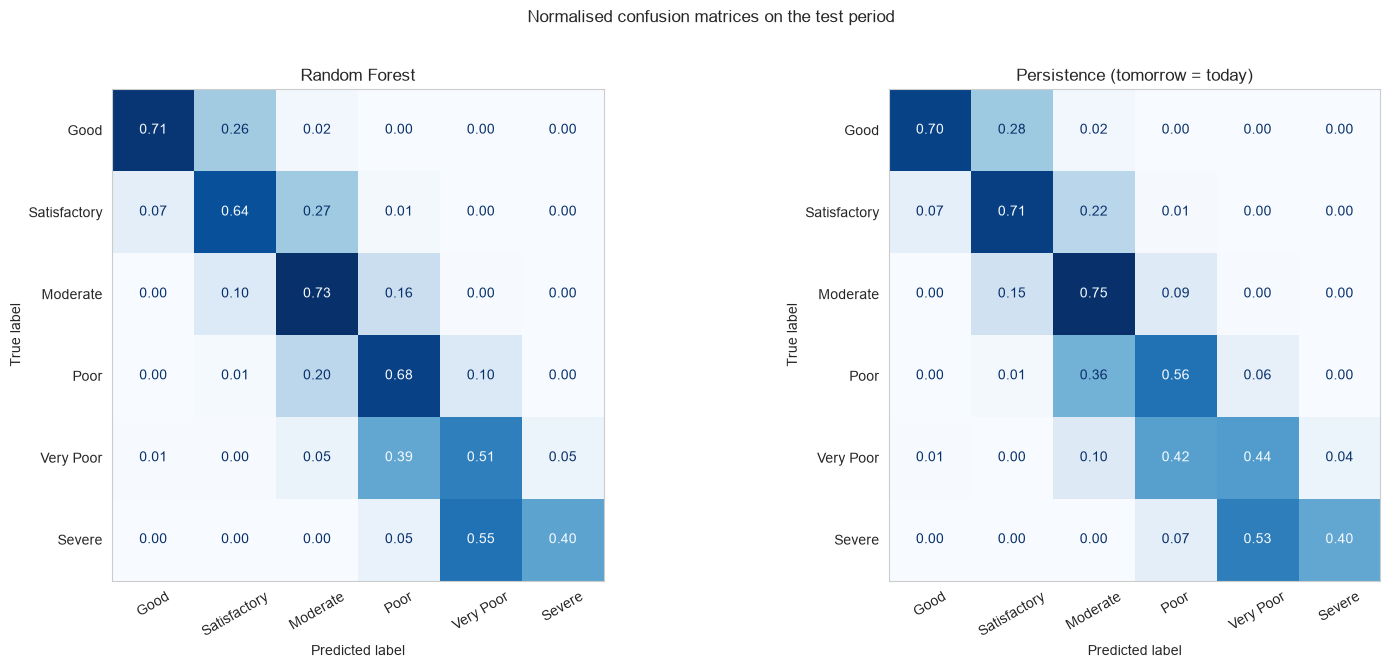

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (title, pred) in zip(axes, [(best_clf_name, pred_clf[best_clf_name]),
                                    ("Persistence (tomorrow = today)", test['today_class'])]):
    ConfusionMatrixDisplay.from_predictions(test['y_class'], pred, labels=labels, normalize='true',
                                            cmap='Blues', ax=ax, xticks_rotation=30, values_format='.2f',
                                            colorbar=False)
    ax.set_title(title)
    ax.grid(False)
plt.suptitle("Normalised confusion matrices on the test period", y=1.02)
save("confusion_matrix_best")

**Takeaway:** *(which categories are hardest? Are the errors between neighbouring categories?)*

---
# Part B — Regression: tomorrow's AQI value

## Step 8 — Baselines
- *Persistence:* tomorrow = today.
- *7-day mean:* tomorrow = the average of the last 7 days.

In [9]:
y_tr, y_te = train['target_AQI_next'], test['target_AQI_next']
res_reg = [
    reg_metrics(y_te, test['AQI'], "Baseline: tomorrow = today"),
    reg_metrics(y_te, test['AQI_roll7'], "Baseline: 7-day mean"),
]
pred_reg = {"Baseline: tomorrow = today": test['AQI'].to_numpy()}
pd.DataFrame(res_reg).round(3)

,Model,MAE,RMSE,R2
0,Baseline: tomorrow = today,24.783,37.158,0.672
1,Baseline: 7-day mean,30.651,43.397,0.553


## Step 9 — Train the three regressors

In [10]:
reg_models = {
    'Ridge Regression': Pipeline([('pre', build_preprocessor(FEATURES, scale=True)), ('m', Ridge(alpha=1.0))]),
    'Random Forest': Pipeline([('pre', build_preprocessor(FEATURES)),
                               ('m', RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                           n_jobs=-1, random_state=42))]),
    'Hist Gradient Boosting': Pipeline([('pre', build_preprocessor(FEATURES)),
                                        ('m', HistGradientBoostingRegressor(random_state=42))]),
}

fitted_reg = {}
for name, model in reg_models.items():
    t0 = time.time()
    model.fit(X_train, y_tr)
    fitted_reg[name] = model
    pred_reg[name] = model.predict(X_test)
    res_reg.append(reg_metrics(y_te, pred_reg[name], name))
    print(f"{name:25s} trained in {time.time() - t0:5.1f}s")

res_reg_df = pd.DataFrame(res_reg).sort_values('MAE').reset_index(drop=True)
res_reg_df.round(3)

Ridge Regression          trained in   1.5s
Random Forest             trained in 212.8s
Hist Gradient Boosting    trained in   6.4s


,Model,MAE,RMSE,R2
0,Hist Gradient Boosting,23.505,33.854,0.728
1,Random Forest,23.531,33.976,0.726
2,Ridge Regression,23.614,33.918,0.727
3,Baseline: tomorrow = today,24.783,37.158,0.672
4,Baseline: 7-day mean,30.651,43.397,0.553


## Step 10 — Tune gradient boosting (time-ordered CV)

In [11]:
if RUN_TUNING:
    grid = {'m__learning_rate': [0.05, 0.1], 'm__max_leaf_nodes': [15, 31]}
    gs = GridSearchCV(reg_models['Hist Gradient Boosting'], grid, cv=TimeSeriesSplit(n_splits=4),
                      scoring='neg_mean_absolute_error', n_jobs=1)
    gs.fit(X_train, y_tr)
    print("Best parameters:", gs.best_params_, "| CV MAE:", round(-gs.best_score_, 2))

    name = 'Hist Gradient Boosting (tuned)'
    fitted_reg[name] = gs.best_estimator_
    pred_reg[name] = gs.best_estimator_.predict(X_test)
    res_reg.append(reg_metrics(y_te, pred_reg[name], name))
    res_reg_df = pd.DataFrame(res_reg).sort_values('MAE').reset_index(drop=True)
res_reg_df.round(3)

Best parameters: {'m__learning_rate': 0.1, 'm__max_leaf_nodes': 15} | CV MAE: 20.88


,Model,MAE,RMSE,R2
0,Hist Gradient Boosting,23.505,33.854,0.728
1,Hist Gradient Boosting (tuned),23.508,33.858,0.728
2,Random Forest,23.531,33.976,0.726
3,Ridge Regression,23.614,33.918,0.727
4,Baseline: tomorrow = today,24.783,37.158,0.672
5,Baseline: 7-day mean,30.651,43.397,0.553


**Takeaway:** *(by how many AQI points does the best model beat persistence? MAE is in AQI units, so this is easy to explain.)*

## Step 11 — Predicted vs actual

Best regressor (by MAE): Hist Gradient Boosting


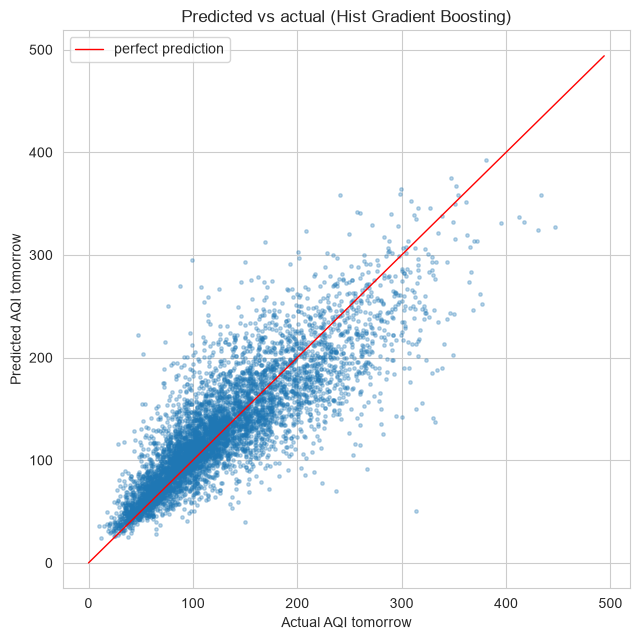

In [12]:
best_reg_name = min(fitted_reg, key=lambda n: mean_absolute_error(y_te, pred_reg[n]))
print("Best regressor (by MAE):", best_reg_name)

samp = np.random.default_rng(0).choice(len(test), size=min(6000, len(test)), replace=False)
plt.figure(figsize=(6.5, 6.5))
plt.scatter(y_te.to_numpy()[samp], pred_reg[best_reg_name][samp], s=6, alpha=0.3)
lim = [0, max(y_te.max(), pred_reg[best_reg_name].max())]
plt.plot(lim, lim, color='red', lw=1, label='perfect prediction')
plt.xlabel("Actual AQI tomorrow"); plt.ylabel("Predicted AQI tomorrow")
plt.title(f"Predicted vs actual ({best_reg_name})"); plt.legend()
save("pred_vs_actual")

## Step 12 — One city over the test winter

## Step 13 — Save results, predictions and models
The analysis notebook (05) reads these files. Model files (`*.pkl`) are in `.gitignore`, so teammates regenerate them by running this notebook.

## Summary 
- A results table for each task: baselines vs three models (`results_*_2023_25.csv`).
- A clear statement of whether the models beat persistence, and by how much, on a **test winter**.
- The confusion matrix and the per-class report for the best classifier.
- Limitations: only about 2.3 years of data, a single test winter, no pollutant concentrations, and the Diwali effect is based on two festivals.


